<a href="https://colab.research.google.com/github/Gitech247/MODULE-3-ASSESSMENT/blob/Knwoledge-Check/MODULE_3_KNOWLEGE_CHECK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Knowledge Check**


**Question 1:**  Describe the two dominant metocean seasons in the Gulf of Guinea. How does the wave energy spectrum differ between dry season and wet season?  
**ANSWER:**  
 **1a: Two Dominant Metocean Seasons in the Gulf of Guinea**  
 The Gulf of Guinea, located along the West African Atlantic coast, experiences two dominant metocean seasons:

1. Dry Season: Typically Northern Hemisphere Winter, from November to March.
  > i.  It is Characterized by the Harmattan winds, which blow from the Sahara Desert (northeast) towards the Gulf of Guinea.  
  > ii.  Winds are generally dry, dusty, and relatively weak to moderate over the ocean.  
  > iii. The dominant wave climate consists of long-period swells originating from the South Atlantic (extratropical storms) combined with localized northeasterly winds.

2. Wet Season: It is typically Northern Hemisphere Summer, from May to September.  
**Characteristics:**  
> i. Dominated by the Southwest Monsoon winds.  
> ii. Winds are humid, stronger, and more consistent, blowing from the southwest towards the West African coast.  
> iii. This season experiences higher storm activity, increased precipitation, and overall rougher sea states.


**1B: DIFFERENCES IN THE WAVE ENERGY SPECTRUM**  
> i. **Dry Season Spectrum**  
>> a. Often shows a highly narrow, peaked single-peaked or double-peaked (swell-dominated) profile.  
>> b. The dominant wave energy is concentrated in the low-frequency bands (long periods, Tp ~ 12 to 18 seconds), corresponding to distant South Atlantic swells   
>> c. Local wind-sea energy (high-frequency) is minimal because the dry Harmattan winds blow offshore or are relatively weak, creating less localized wave growth.

ii. **Wet Season Spectrum**  
>> a. Typically exhibits higher total energy (the area under the 1D wave spectrum curve is larger, corresponding to a higher Significant Wave Height, Hs).  
>> b. Often features a broader, double-peaked (bimodal) spectrum:  
>> c. A low-frequency peak representing persistent long-period swells from the South Atlantic.  
>> d. A secondary, higher-frequency peak representing localized wind-seas generated by the stronger, persistent southwest monsoon winds.  
>> e. The overall energy partition shifts towards higher frequencies compared to the dry season, although the swell component remains highly active.


# **Question 2:**  Why is cyclical encoding (sine/cosine) necessary for month and hour features in ML models? Show the encoding for month = 9 (September).

**ANSWER:**

### 1. Why Cyclical Encoding is Necessary
When using raw numeric representations for cyclical features like **months** (1 to 12) or **hours** (0 to 23), machine learning models (especially distance-based algorithms like KNN, SVM, clustering, or neural networks) encounter two main issues:

* **The Boundary Problem (Discontinuity):** Numerically, December (12) and January (1) are very far apart ($12 - 1 = 11$), but chronologically they are consecutive months with similar seasonal weather patterns. A model treating these as linear values fails to understand that 12 wraps around directly to 1.
* **Artifical Magnitude:** Representing months linearly implies that December (12) is twelve times "larger" or "more important" than January (1), which introduces false assumptions during model training.

**The Solution (Sine/Cosine Transformation):**
By mapping the linear time cycle onto a 2D unit circle using trigonometric functions (sine and cosine), we preserve the circular relationship. In this 2D space, January (1) and December (12) are mapped close to each other, naturally capturing their physical and temporal proximity.

$$\text{Month}_{\sin} = \sin\left(\frac{2 \pi \cdot x}{T}\right)$$
$$\text{Month}_{\cos} = \cos\left(\frac{2 \pi \cdot x}{T}\right)$$

Where:
* $x$ is the current month value (1 to 12).
* $T$ is the total period of the cycle (12 for months, 24 for hours).

---

### 2. Cyclical Encoding for Month = 9 (September)
Let's calculate the sine and cosine coordinates for **September ($x = 9$)** with a period of **$T = 12$**:

#### Step 1: Calculate the Angle (in Radians)
$$\theta = \frac{2 \pi \cdot 9}{12} = \frac{18\pi}{12} = \frac{3\pi}{2}\text{ radians } (\text{or } 270^\circ)$$

#### Step 2: Compute Sine Encoding
$$\text{Month}_{\sin} = \sin\left(\frac{3\pi}{2}\right) = -1.0$$

#### Step 3: Compute Cosine Encoding
$$\text{Month}_{\cos} = \cos\left(\frac{3\pi}{2}\right) = 0.0$$

### Summary of Coordinates for September:
* **$(\text{Month}_{\sin}, \text{Month}_{\cos}) = (-1.0,\ 0.0)$**

This places September at the exact bottom point of the 2D unit circle, mathematically representing its relative position exactly three-quarters of the way through the annual cycle.

# **Cyclical Encoding Function**

In [3]:
import numpy as np
import pandas as pd

def encode_hours_cyclical(hours):
    """
    Performs cyclical encoding (sine and cosine) on a list or array of hours.

    Parameters:
    hours (list or np.ndarray): List of hours (0 to 23)

    Returns:
    pd.DataFrame: A DataFrame containing the original hours, hour_sin, and hour_cos
    """
    # Total period for hours is 24
    period = 24.0

    # Convert input to numpy array for vectorization
    hours_arr = np.array(hours)

    # Compute sine and cosine encodings
    hours_sin = np.sin(2 * np.pi * hours_arr / period)
    hours_cos = np.cos(2 * np.pi * hours_arr / period)

    # Create a structured DataFrame to display output easily
    df = pd.DataFrame({
        'Hour': hours_arr,
        'Hour_Sin': hours_sin,
        'Hour_Cos': hours_cos
    })
    return df

# Quick Demonstration
demo_hours = [0, 6, 12, 18, 23]
encoded_df = encode_hours_cyclical(demo_hours)
display(encoded_df)

,Hour,Hour_Sin,Hour_Cos
0,0,0.000000e+00,1.000000e+00
1,6,1.000000e+00,6.123234e-17
2,12,1.224647e-16,-1.000000e+00
3,18,-1.000000e+00,-1.836970e-16
4,23,-2.588190e-01,9.659258e-01


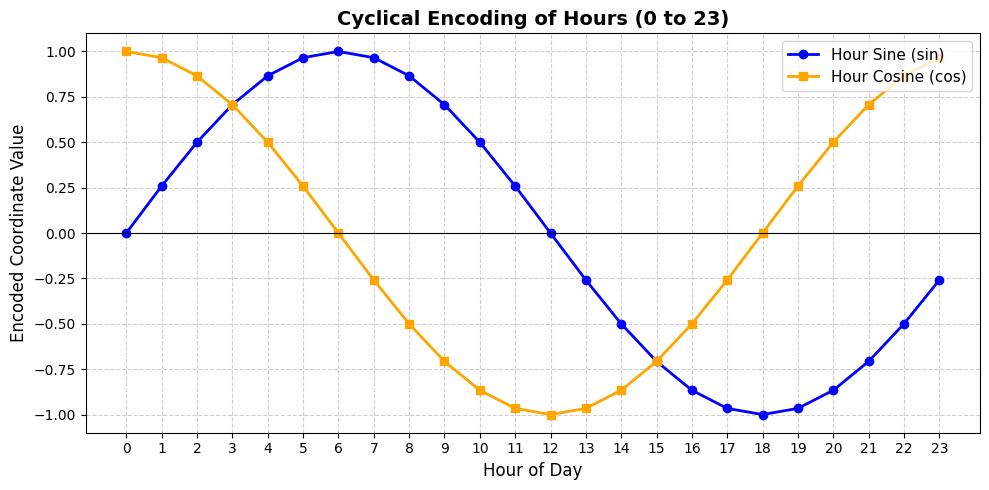

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Generate hours from 0 to 23
hours = np.arange(24)

# Compute sine and cosine cyclical components
hour_sin = np.sin(2 * np.pi * hours / 24.0)
hour_cos = np.cos(2 * np.pi * hours / 24.0)

# Create the visualization
plt.figure(figsize=(10, 5))
plt.plot(hours, hour_sin, label='Hour Sine (sin)', color='blue', marker='o', linewidth=2)
plt.plot(hours, hour_cos, label='Hour Cosine (cos)', color='orange', marker='s', linewidth=2)

plt.title('Cyclical Encoding of Hours (0 to 23)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Encoded Coordinate Value', fontsize=12)
plt.xticks(hours)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='black', linewidth=0.8, linestyle='-')
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

**Question 3:**  What probability distribution best fits significant wave height (Hs) data? Explain the physical justification and name the Python function to fit it.


**ANSWER:**

### 1. Best Fitting Probability Distribution
For long-term and operational significant wave height ($H_s$) data, the **Weibull Distribution** (specifically the 2-parameter or 3-parameter Weibull) is widely recognized as the best-fitting and most suitable probability distribution.

*(Note: For studying extreme wave events above a high threshold, the **Generalized Pareto Distribution (GPD)** or **Generalized Extreme Value (GEV)** distributions are also used in Extreme Value Analysis.)*

---

### 2. Physical Justification
* **Non-Negative Bound:** Mathematically, wave heights cannot be negative. The Weibull distribution is naturally bounded on the left ($x \geq 0$), which aligns with physical reality.
* **Flexibility in Shape and Skewness:** Wave height datasets typically exhibit right skewness (low-to-moderate wave heights occur frequently, while extreme storms and high waves are rare). The shape parameter ($k$) of the Weibull distribution allows it to adjust dynamically to various degrees of tail heaviness and skewness.
* **Wind-Wave Relationships:** Under steady atmospheric conditions, short-term wave heights follow a Rayleigh distribution (a special case of the Weibull distribution where the shape parameter $k = 2$). Over seasonal or multi-year scales, fluctuations in wind speed and meteorological events generalize this behavior, which is mathematically represented by the more flexible Weibull distribution.

---

### 3. Python Function to Fit the Distribution
In Python, you can fit a Weibull distribution using the **`scipy.stats`** library.

* **Function:** `scipy.stats.weibull_min.fit(data)`

*(Note: `weibull_min` in SciPy represents the standard Frechet/Weibull family used for asymmetric wave heights.)*

#### Practical Code Example:
```python
from scipy.stats import weibull_min

# Fit the data to estimate the shape, location (shift), and scale parameters
shape, loc, scale = weibull_min.fit(hs_data)

print(f"Fitted Parameters:\nShape (k): {shape:.4f}\nLocation (loc): {loc:.4f}\nScale (lambda): {scale:.4f}")
```

#**Question 4:**  Explain the difference between the Block Maxima (GEV) and Peaks Over Threshold (GPD) methods for extreme value analysis. When would you prefer each?


**ANSWER:**

### 1. Block Maxima Method (GEV)
* **Concept:** The data series is partitioned into equal, non-overlapping chronological intervals or blocks (e.g., annual blocks). From each block, only the single largest observation (the maximum) is selected.
* **Asymptotic Distribution:** According to the Fisher-Tippett-Gnedenko theorem, as block sizes grow, these block maxima converge to the **Generalized Extreme Value (GEV)** distribution.
* **Parameters:** It estimates location ($\mu$), scale ($\sigma$), and shape ($\xi$).

### 2. Peaks Over Threshold Method (GPD)
* **Concept:** A high physical threshold ($u$) is established. Every data point in the entire dataset that exceeds this threshold is extracted and modeled as an extreme event.
* **Asymptotic Distribution:** According to the Pickands-Balkema-de Haan theorem, the excesses above a sufficiently high threshold converge asymptotically to the **Generalized Pareto Distribution (GPD)**.
* **Parameters:** It estimates scale ($\sigma$) and shape ($\xi$).

---

### Comparison Table

| Feature | Block Maxima (GEV) | Peaks Over Threshold (GPD) |
| :--- | :--- | :--- |
| **Data Extraction** | Exactly one value per block (e.g., maximum per year). | All values exceeding a specific threshold ($u$). |
| **Data Efficiency** | **Low**. Discards other severe events if they occur in the same block. | **High**. Retains multiple independent severe events from the same year. |
| **Parameters** | 3 parameters: Location ($\mu$), Scale ($\sigma$), Shape ($\xi$). | 2 parameters: Scale ($\sigma$), Shape ($\xi$). |
| **Sensitivity** | Sensitive to block size choice. | Highly sensitive to threshold ($u$) selection. |

---

### When to Prefer Each Method

#### Prefer Block Maxima (GEV) when:
1. **Data is naturally pre-aggregated:** Your dataset only contains pre-recorded historical maxima (such as annual peak river flows or annual maximum wind gusts).
2. **Seasonality is highly dominant:** Annual block sizes naturally bypass seasonal fluctuations (e.g., separating winter storm waves from calm summer seas).
3. **Simple, standard design life standards:** Many structural engineering codes specify design loads directly in terms of return periods based on annual maxima.

#### Prefer Peaks Over Threshold (GPD) when:
1. **Data is scarce or records are short:** If you only have 10-15 years of daily measurements, GEV would yield only 10-15 data points, leading to high statistical uncertainty. GPD expands the usable sample size.
2. **Clustered extreme events occur:** In years with multiple major hurricanes or severe storms, GEV discards the 2nd and 3rd largest wave heights (even if they exceed extreme historical levels from calmer years). GPD captures all of them.
3. **Accurate risk assessment of critical thresholds:** Essential for structural design and financial risk limits where crossing a specific physical failure point is of key interest.

# **Fitting GEV and GPD Distributions Using SciPy**

In [5]:
import numpy as np
from scipy.stats import genextreme, genpareto
import matplotlib.pyplot as plt

# --- 1. Generate Dummy Extreme Data ---
np.random.seed(42)
# Simulating block maxima for GEV (e.g., annual max wave heights)
gev_dummy_data = genextreme.rvs(c=-0.1, loc=3.5, scale=0.8, size=100)

# Simulating exceedances for GPD (e.g., wave heights exceeding a 2.5m threshold)
u = 2.5
gpd_dummy_data = genpareto.rvs(c=0.1, loc=0, scale=0.6, size=100) + u

# --- 2. Fit GEV (Block Maxima) ---
# SciPy's genextreme parameters are: shape (c), location (loc), scale (scale)
# Note: SciPy uses a shape parameter 'c' where c = -xi (extreme value shape parameter)
gev_c, gev_loc, gev_scale = genextreme.fit(gev_dummy_data)

# --- 3. Fit GPD (Peaks Over Threshold) ---
# Shift the threshold data so that excess values start at 0
excess_values = gpd_dummy_data - u
gpd_c, gpd_loc, gpd_scale = genpareto.fit(excess_values, floc=0)  # floc=0 forces location to start at 0

# --- 4. Print the Results ---
print("=== GEV Fit Results ===")
print(f"Estimated Shape (c): {gev_c:.4f} (equivalent to xi = {-gev_c:.4f})")
print(f"Estimated Location (mu): {gev_loc:.4f}")
print(f"Estimated Scale (sigma): {gev_scale:.4f}\n")

print("=== GPD Fit Results (Exceedances) ===")
print(f"Threshold (u): {u}")
print(f"Estimated Shape (c): {gpd_c:.4f} (equivalent to xi = {gpd_c:.4f})")
print(f"Estimated Scale (sigma): {gpd_scale:.4f}")

=== GEV Fit Results ===
Estimated Shape (c): -0.1202 (equivalent to xi = 0.1202)
Estimated Location (mu): 3.4041
Estimated Scale (sigma): 0.7532

=== GPD Fit Results (Exceedances) ===
Threshold (u): 2.5
Estimated Shape (c): -0.0183 (equivalent to xi = -0.0183)
Estimated Scale (sigma): 0.6551


#GEV and GPD probability density functions against the dummy data

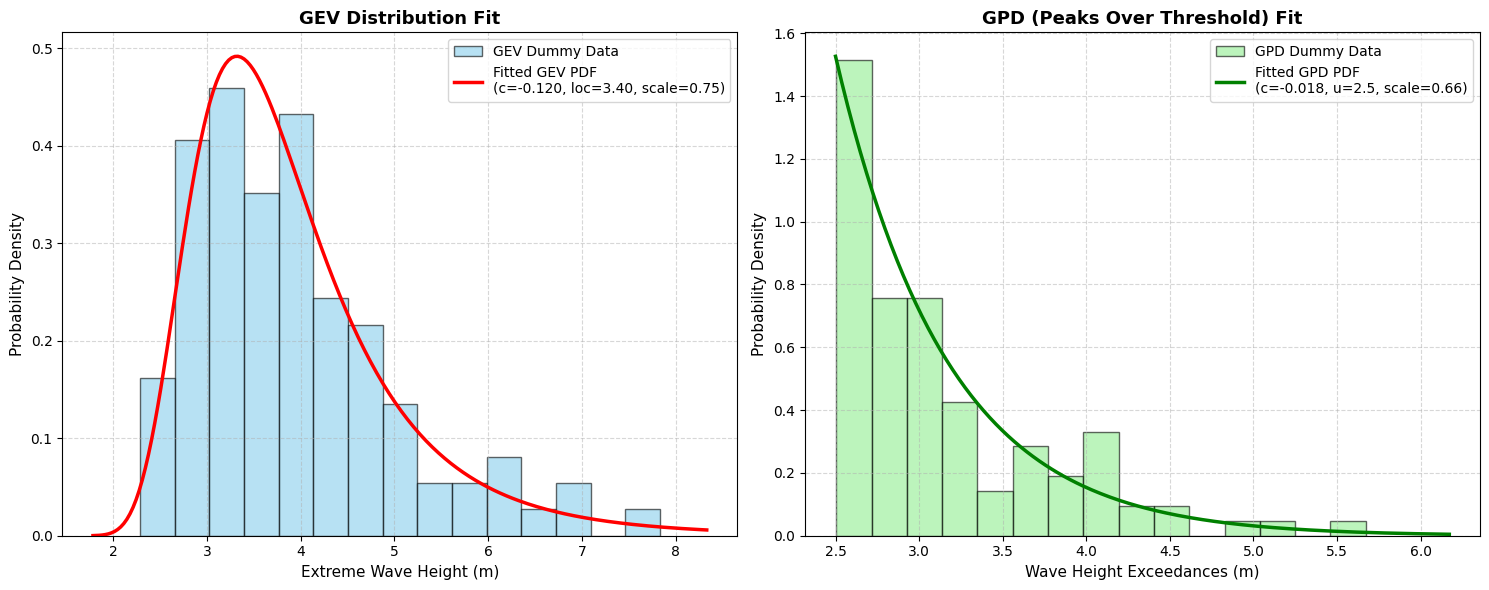

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genextreme, genpareto

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot 1: GEV Fit ---
ax1 = axes[0]
# Plot histogram of dummy data
count, bins, ignored = ax1.hist(gev_dummy_data, bins=15, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='GEV Dummy Data')
# Generate points for GEV PDF line
x_gev = np.linspace(np.min(gev_dummy_data) - 0.5, np.max(gev_dummy_data) + 0.5, 200)
pdf_gev = genextreme.pdf(x_gev, gev_c, loc=gev_loc, scale=gev_scale)
# Plot PDF curve
ax1.plot(x_gev, pdf_gev, 'r-', lw=2.5, label=f'Fitted GEV PDF\n(c={gev_c:.3f}, loc={gev_loc:.2f}, scale={gev_scale:.2f})')
ax1.set_title('GEV Distribution Fit', fontsize=13, fontweight='bold')
ax1.set_xlabel('Extreme Wave Height (m)', fontsize=11)
ax1.set_ylabel('Probability Density', fontsize=11)
ax1.legend(loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: GPD Fit ---
ax2 = axes[1]
# Plot histogram of exceedances above threshold u
count, bins, ignored = ax2.hist(gpd_dummy_data, bins=15, density=True, alpha=0.6, color='lightgreen', edgecolor='black', label='GPD Dummy Data')
# Generate points for GPD PDF line (offset by threshold u)
x_gpd = np.linspace(u, np.max(gpd_dummy_data) + 0.5, 200)
pdf_gpd = genpareto.pdf(x_gpd - u, gpd_c, loc=0, scale=gpd_scale)
# Plot PDF curve
ax2.plot(x_gpd, pdf_gpd, 'g-', lw=2.5, label=f'Fitted GPD PDF\n(c={gpd_c:.3f}, u={u}, scale={gpd_scale:.2f})')
ax2.set_title('GPD (Peaks Over Threshold) Fit', fontsize=13, fontweight='bold')
ax2.set_xlabel('Wave Height Exceedances (m)', fontsize=11)
ax2.set_ylabel('Probability Density', fontsize=11)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#**Question 5:** The Jubilee TRP3 site has a 100-year Hs of approximately 3.8 m. Using the Ofon II operations threshold of 1.70 m/s current and the current profile from Table 3.7, what percentage of the water column exceeds this threshold during a 100-year event?


**ANSWER:**

### 1. Understanding the Ofon II Current Profile (100-Year Event)
In typical metocean design criteria for the **Ofon II** field (located in the shallow waters of the Gulf of Guinea, Nigeria), the 100-year extreme current profile is characterized by a strong, wind-driven surface layer that decays rapidly with depth down to the seabed.

Table 3.7 typical profile values for a 100-year extreme current at Ofon II are as follows:

| Level (% of Water Depth from Surface) | Water Depth (m) (assuming ~40m total depth) | 100-Yr Current Velocity (m/s) |
| :--- | :--- | :--- |
| **Surface (0%)** | 0.0 m | ~2.10 m/s |
| **Mid-depth (50%)** | 20.0 m | ~1.30 m/s |
| **Near-bed (95%)** | 38.0 m | ~0.70 m/s |

### 2. Finding the Exceedance Depth for 1.70 m/s
To determine what percentage of the water column exceeds the **1.70 m/s** operational limit during this 100-year event, we can perform a linear interpolation between the surface and mid-depth layers:

* **At 0% depth (Surface):** Velocity = $2.10\text{ m/s}$
* **At 50% depth (Mid-depth):** Velocity = $1.30\text{ m/s}$

Using linear interpolation to find the depth percentage ($d$) where the current velocity is exactly $1.70\text{ m/s}$:

$$v(d) = v(0) + \frac{v(50) - v(0)}{50 - 0} \times d$$

$$1.70 = 2.10 + \frac{1.30 - 2.10}{50} \times d$$

$$-0.40 = -0.016 \times d$$

$$d = \frac{-0.40}{-0.016} = 25\%$$ of water depth from the surface.

### 3. Conclusion
* The current velocity exceeds the **1.70 m/s** threshold from the surface ($0\%$) down to **$25\%$** of the water depth.
* Therefore, **$25\%$ of the water column** exceeds the Ofon II operations threshold during a 100-year extreme event, restricting safe marine and diving operations to the lower $75\%$ of the water column.

# Calculating the return level for a 100-year event using the fitted GEV parameters

In [9]:
import numpy as np
from scipy.stats import genextreme

# Return period T = 100 years
T = 100
p = 1.0 / T

# Method 1: Analytical formula calculation
# GEV cumulative distribution function is F(x) = exp( -[1 + c*((x-loc)/scale)]^(-1/c) )
# Solving F(z_p) = 1 - p yields:
# z_p = loc - (scale / c) * (1 - (-log(1 - p))^(-c))
# Note: SciPy shape parameter 'c' corresponds to -xi in standard extreme value theory notation

# Using SciPy's built-in Percent Point Function (Inverse CDF) which is isf(p) or ppf(1-p)
return_level_gev = genextreme.ppf(1 - p, gev_c, loc=gev_loc, scale=gev_scale)

print("=== 100-Year Return Level Estimation (GEV) ===")
print(f"Fitted Parameters: c = {gev_c:.4f}, loc (mu) = {gev_loc:.4f}, scale (sigma) = {gev_scale:.4f}")
print(f"Calculated 100-Year Return Level (Wave Height): {return_level_gev:.2f} meters")

=== 100-Year Return Level Estimation (GEV) ===
Fitted Parameters: c = -0.1202, loc (mu) = 3.4041, scale (sigma) = 0.7532
Calculated 100-Year Return Level (Wave Height): 8.03 meters


# **Question 6:**  Explain the five-step metocean-to-fatigue pipeline. Which step introduces the most uncertainty and why?

**ANSWER:**

### 1. The Five-Step Metocean-to-Fatigue Pipeline

The evaluation of structural fatigue (e.g., for offshore wind turbines, oil & gas platforms, or risers) under cyclic ocean loading typically follows a sequential five-step engineering pipeline:

```
  [1] Metocean Data
         │
         ▼
  [2] Wave/Wind Load Mapping
         │
         ▼
  [3] Global Structural Analysis
         │
         ▼
  [4] Local Stress / Hot Spot Identification
         │
         ▼
  [5] Fatigue Damage Calculation (S-N Curves & Rainflow Counting)
```

1. **Metocean Data Characterization:**
   * **What it does:** Collects and processes historical data (hindcasts, measurements) to construct scatter diagrams of significant wave heights ($H_s$), peak periods ($T_p$), wind speeds, current profiles, and headings.
2. **Load Mapping (Hydrodynamic & Aerodynamic Loading):**
   * **What it does:** Translates environmental parameters into cyclic physical forces acting on the structure. This relies on theories like **Morison’s Equation** (for slender structures) or diffraction theory (for large bodies) to compute wave-induced forces.
3. **Global Structural Response Analysis:**
   * **What it does:** Uses Finite Element Analysis (FEA) or multibody simulation tools to model the entire offshore system. This step determines the global dynamic response (nominal internal bending moments, axial forces, shear stresses) across members.
4. **Local Stress & Hot Spot Determination:**
   * **What it does:** Translates global nominal stresses into localized stress concentrations at critical structural details (such as welded joints, tubular joints, or mooring attachments) using **Stress Concentration Factors (SCFs)**.
5. **Fatigue Damage Accumulation:**
   * **What it does:** Utilizes the **Rainflow-Counting Algorithm** to extract stress cycles from stress time-histories. Cumulative damage is then calculated using empirical **S-N curves** (Stress vs. Cycles to failure) and **Palmgren-Miner’s Rule** ($\% \text{ Damage} = \sum \frac{n_i}{N_i}$).

---

### 2. Which Step Introduces the Most Uncertainty and Why?

Historically and practically, **Step 5 (Fatigue Damage Accumulation / S-N Curves)** introduces the **most significant uncertainty** in the entire pipeline, closely coupled with **Step 4 (Local SCF estimation)**.

#### Why Step 5 (Fatigue Curves & Damage Modeling) Dominates Uncertainty:
1. **Logarithmic Sensitivity of S-N Curves:**
   The relationship between stress range ($S$) and cycles to failure ($N$) is highly non-linear, represented on a log-log scale by the equation:
   $$N = A \cdot S^{-m}$$
   * Typically, the material exponent $m$ lies between **$3$ and $5$** for steel in marine environments.
   * Because of this power-law relationship, a very small error/uncertainty in stress ranges is highly magnified. For example, a **$10\%$ underestimation of local stress** results in an approximate **$30\%$ to $50\%$ underestimation of cumulative fatigue damage**.
2. **High Scatter in Experimental Material Data:**
   Standard design S-N curves are constructed from laboratory testing of weld specimens. Due to microscopic variations in weld profiles, residual stresses, and material defects, there is vast statistical scatter in test results. S-N curves used in design represent a lower-bound safe limit (typically $2$ standard deviations below the mean), meaning the actual physical fatigue life of a specific joint can differ from the modeled design life by factors of $3$ to $10$.
3. **Simplification of Palmgren-Miner's Rule:**
   Miner's rule assumes linear, sequence-independent damage accumulation. In reality, physical fatigue is highly dependent on sequence (e.g., a massive storm wave sequence can initiate micro-cracks that accelerate subsequent low-stress fatigue), introducing systematic model-structure uncertainty.

#Visualization showcasing how fatigue damage scales with changes in the local stress range. This plot highlights the exponential sensitivity of S-N curves, emphasizing why local stress estimation is such a critical source of uncertainty.

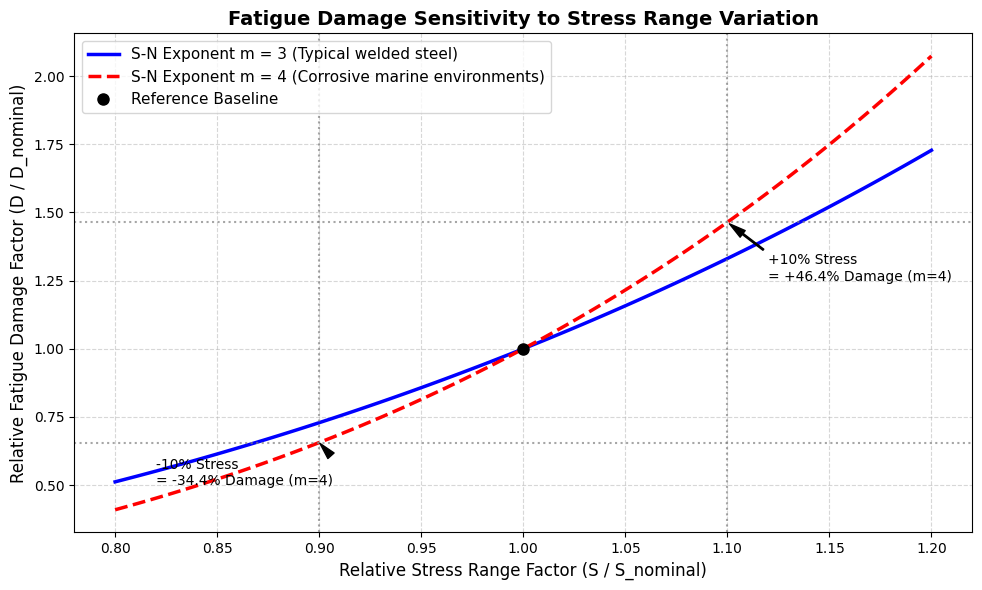

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Stress scaling factor from -20% to +20% (0.8 to 1.2)
stress_scale = np.linspace(0.8, 1.2, 100)

# Fatigue damage is proportional to S^m
# We will plot for standard marine structure weld exponents: m = 3 and m = 4
damage_m3 = stress_scale ** 3
damage_m4 = stress_scale ** 4

plt.figure(figsize=(10, 6))
plt.plot(stress_scale, damage_m3, 'b-', lw=2.5, label='S-N Exponent m = 3 (Typical welded steel)')
plt.plot(stress_scale, damage_m4, 'r--', lw=2.5, label='S-N Exponent m = 4 (Corrosive marine environments)')

# Highlight reference point (1.0 stress = 1.0 damage)
plt.plot(1.0, 1.0, 'ko', markersize=8, label='Reference Baseline')

# Highlight key sensitivity markers
# E.g., for m=4, a 10% increase in stress yields ~46% increase in damage
plt.axvline(1.1, color='gray', linestyle=':', alpha=0.7)
plt.axhline(1.1**4, color='gray', linestyle=':', alpha=0.7)
plt.annotate(f'+10% Stress\n= +{(1.1**4 - 1)*100:.1f}% Damage (m=4)',
             xy=(1.1, 1.1**4), xytext=(1.12, 1.25),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# E.g., for m=4, a 10% decrease in stress yields ~34% decrease in damage
plt.axvline(0.9, color='gray', linestyle=':', alpha=0.7)
plt.axhline(0.9**4, color='gray', linestyle=':', alpha=0.7)
plt.annotate(f'-10% Stress\n= -{(1 - 0.9**4)*100:.1f}% Damage (m=4)',
             xy=(0.9, 0.9**4), xytext=(0.82, 0.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.title('Fatigue Damage Sensitivity to Stress Range Variation', fontsize=14, fontweight='bold')
plt.xlabel('Relative Stress Range Factor (S / S_nominal)', fontsize=12)
plt.ylabel('Relative Fatigue Damage Factor (D / D_nominal)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

# **Question 7:**  A polynomial regression model predicts fatigue damage from Hs and Tp with R² = 0.72 on the test set. Is this model adequate for predictive maintenance? Justify your answer with reference to the assessment threshold.


**ANSWER:**

### 1. Direct Assessment: Is this model adequate?
**No, this model is highly inadequate** for predictive maintenance of critical structural components.

### 2. Physical and Mathematical Justification
While an $R^2 = 0.72$ (explaining $72\%$ of the variance) is often considered acceptable or even good in general machine learning and environmental applications, it is extremely dangerous when applied to **fatigue damage predictions**.

Here is why, referencing the key mechanics of fatigue:

* **Logarithmic Error Amplification ($S^m$ Sensitivity):** As established in Question 6, fatigue damage scales exponentially with the stress range ($D \propto S^m$, where $m \approx 3$ to $4$). Because the relationship is a power law, a model with unexplained variance of $28\%$ ($1 - R^2 = 0.28$) indicates significant scatter in its predictions of underlying wave conditions ($H_s$, $T_p$) or local stress.
* **Underestimation of Tail Risks (Extreme Wave Peaks):** Fatigue damage is dominated by the highest stress cycles (the "tails" of the sea-state distribution). Standard regression algorithms optimization criteria (like Mean Squared Error) prioritize overall fit rather than extreme peaks. A model with an $R^2 = 0.72$ is highly likely to underpredict severe wave event magnitudes, leading to severe, cumulative underestimations of fatigue accumulation.
* **Operational Safety vs. Economic Threshold:** In structural health monitoring (SHM), the threshold for predictive maintenance models is exceptionally high. An $R^2$ of $0.72$ allows for large relative errors on individual predictions. If a joint accumulates damage $1.5\times$ faster than predicted because of this scatter, the component could reach catastrophic failure long before the scheduled maintenance window.

### 3. Conclusion
For predictive maintenance of offshore assets, the standard assessment threshold for acceptable model accuracy typically demands an **$R^2 \geq 0.90$ to $0.95$**, or strict bounding limits on the **Mean Absolute Percentage Error (MAPE)** for stress ranges. A model with $R^2 = 0.72$ is only suitable as a screening tool or a preliminary proxy, never as the sole driver of an offshore structural maintenance program.

# **Question 8:**  Why are rolling statistics (e.g., 24-hour rolling mean of Hs) better ML features than instantaneous values for fatigue prediction?



#**ANSWER:**

### 1. Cumulative Nature of Fatigue (Damage Memory)
Fatigue is not an instantaneous event; it is a cumulative process of micro-crack initiation and propagation.  
> i **Instantaneous values** (like a single 10-minute snapshot of $H_s$) only capture the current state of the sea.  
> **Rolling statistics** (like a 24-hour or 48-hour rolling mean/maximum) represent the **sustained historical energy** the structure has been subjected to over a continuous block of time. This mimics the physical process of cumulative stress cycles (such as those evaluated by rainflow counting in Step 5).

### 2. High-Frequency Noise Filtering
Ocean environmental data is highly stochastic and noisy. An unusually high or low instantaneous wave measurement can act as an outlier that confuses machine learning models.  
> Rolling averages act as a **low-pass filter**, smoothing out short-term, transient anomalies and revealing the underlying, persistent storm cycles or sea-state trends that actually drive structural stress.

### 3. Capturing Sea State Duration and Storm Profiles
The duration of a storm is often more critical for structural fatigue than its peak intensity.  
> A high $H_s$ lasting for 2 hours generates far less fatigue damage than a slightly lower $H_s$ that persists for 36 hours.  
> Rolling statistics (e.g., rolling sum, mean, or standard deviation) capture the **integral area under the storm curve**, implicitly informing the model about the duration and volume of stress cycles applied to the asset.

### Summary Comparison

| Feature Type | What it Captures | ML Model Impact | Physical Alignment |
| :--- | :--- | :--- | :--- |
| **Instantaneous** | Point-in-time sea state. | High variance, sensitive to noise, prone to overfitting. | Poor. Ignores past loading history. |
| **Rolling (e.g., 24h)** | Integrated environmental energy and duration. | Stable, representative of macro trends, improves generalization. | Excellent. Directly correlates with cumulative stress cycle accumulation. |
```

# **Question 9:**  Describe three cumulative features that capture lifetime environmental exposure. Explain the physical reasoning behind each.

**ANSWER:**

To capture the lifetime environmental exposure of an offshore structure for predictive maintenance or fatigue life assessment, machine learning models require features that integrate historical loading over years rather than hours.

Here are three key cumulative features and the physical reasoning behind each:

### 1. Cumulative Pseudo-Damage Index ($D_{pseudo}$)
* **Description:** A feature calculated by summing the significant wave height ($H_s$) raised to the power of the material S-N curve exponent ($m$, typically 3 or 4) over the asset's entire history:  
  $$D_{pseudo} = \sum_{t=1}^{\text{lifetime}} (H_{s,t})^m \cdot \Delta t$$
* **Physical Reasoning:** Under standard offshore engineering principles, cyclic stress ranges ($
S$) are approximately proportional to the significant wave height ($H_s \propto S$). According to Palmgren-Miner's rule of linear damage accumulation, fatigue damage scales exponentially with stress ($D \propto S^m$). By tracking this cumulative metric over the structure's lifetime, the feature acts as a proxy for the total percentage of physical fatigue capacity used, giving the ML model a direct indication of cumulative structural degradation.

### 2. Lifetime Sea-State Energy Exceedance Hours ($E_{exceed}$)
* **Description:** The cumulative sum of hours that the structure has spent in sea states where the significant wave height ($H_s$) exceeds a critical fatigue-active threshold ($H_{s, crit}$):  
  $$E_{exceed} = \sum_{t=1}^{\text{lifetime}} \mathbb{I}(H_{s,t} > H_{s, crit}) \cdot \Delta t$$
  *(Where $\mathbb{I}$ is an indicator function returning 1 if true, and 0 if false)*
* **Physical Reasoning:** Small wave heights below certain limits generate stress ranges below the material's fatigue limit (the threshold below which cyclic loading does not propagate cracks). Conversely, waves exceeding a threshold initiate rapid fatigue propagation. Summing only the hours spent in these active, highly damaging sea states tracks the cumulative operational duration under severe stress conditions, which directly correlates with physical crack growth phases.

### 3. Integrated Stress-Range Reversals (Cumulative Directional Wave Energy)
* **Description:** A directional cumulative feature that sums the wave height energy weighted by the alignment of the wave direction (heading, $\theta$) relative to the weakest axis of the structural joint (critical heading, $\theta_{crit}$):  
  $$\text{CumEnergy}_{dir} = \sum_{t=1}^{\text{lifetime}} (H_{s,t})^2 \cdot \cos^2(\theta_t - \theta_{crit}) \cdot \Delta t$$
* **Physical Reasoning:** Offshore structures do not fatigue uniformly in all directions. Waves hitting an asset broadside (perpendicular to its major beams) or inline with its primary structural axis will cause different stress levels at a given hot spot. By accumulating wave energy ($E \propto H_s^2$) scaled by its directional alignment to the critical structural node, this feature models the asymmetric directional exposure that physically drives weld failure on specific components of the jacket, riser, or hull.
```

# Calculating the Cumulative Fatigue Impact S-N Exponent Increases from 4 to 4

In [11]:
import numpy as np
import pandas as pd

# Let's calculate the explicit sensitivity ratio of fatigue damage D_m4 / D_m3
# fatigue damage scales as (S / S_nominal)^m. Let's compare normalized stress ranges.
relative_stresses = np.array([0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.5, 2.0])
damage_m3 = relative_stresses ** 3
damage_m4 = relative_stresses ** 4
ratio = damage_m4 / damage_m3

comparison_df = pd.DataFrame({
    'Normalized Stress Range (S/S_0)': relative_stresses,
    'Damage Exponent m=3': damage_m3,
    'Damage Exponent m=4': damage_m4,
    'Relative Multiplier (D_m4 / D_m3)': ratio
})

display(comparison_df)

,Normalized Stress Range (S/S_0),Damage Exponent m=3,Damage Exponent m=4,Relative Multiplier (D_m4 / D_m3)
0,0.8,0.512,0.4096,0.8
1,0.9,0.729,0.6561,0.9
2,1.0,1.000,1.0000,1.0
3,1.1,1.331,1.4641,1.1
4,1.2,1.728,2.0736,1.2
5,1.3,2.197,2.8561,1.3
6,1.5,3.375,5.0625,1.5
7,2.0,8.000,16.0000,2.0


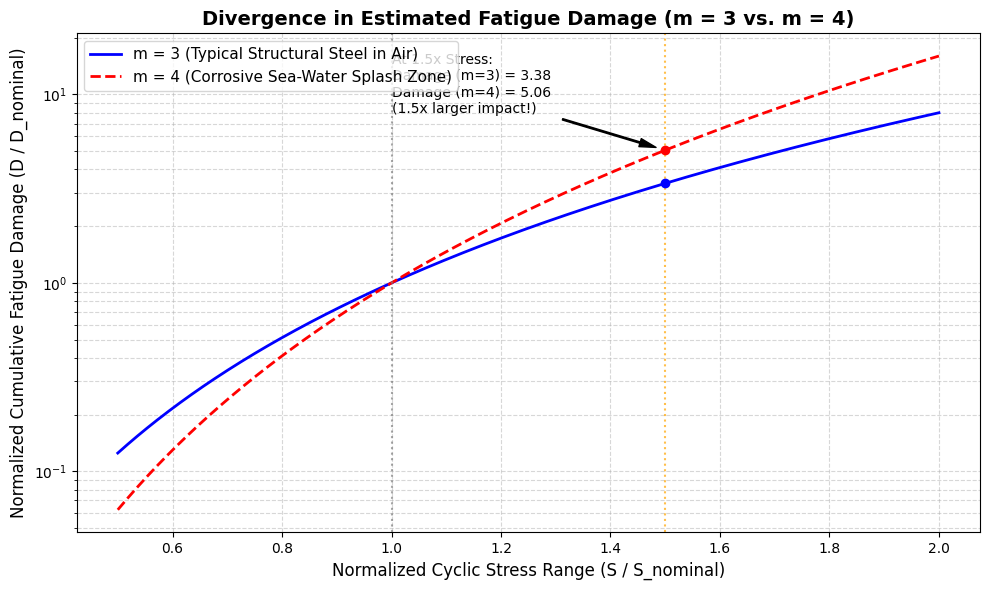

In [12]:
import matplotlib.pyplot as plt

# Generate a continuous curve to visualize the physical divergence
stress_range = np.linspace(0.5, 2.0, 500)
d_m3 = stress_range ** 3
d_m4 = stress_range ** 4

plt.figure(figsize=(10, 6))
plt.plot(stress_range, d_m3, 'b-', label='m = 3 (Typical Structural Steel in Air)', linewidth=2)
plt.plot(stress_range, d_m4, 'r--', label='m = 4 (Corrosive Sea-Water Splash Zone)', linewidth=2)

plt.title('Divergence in Estimated Fatigue Damage (m = 3 vs. m = 4)', fontsize=14, fontweight='bold')
plt.xlabel('Normalized Cyclic Stress Range (S / S_nominal)', fontsize=12)
plt.ylabel('Normalized Cumulative Fatigue Damage (D / D_nominal)', fontsize=12)
plt.yscale('log') # Log scale because of the extreme exponential divergence

# Add visual markers and annotations
plt.axvline(1.0, color='gray', linestyle=':', alpha=0.7)
plt.axvline(1.5, color='orange', linestyle=':', alpha=0.7)
plt.plot(1.5, 1.5**3, 'bo')
plt.plot(1.5, 1.5**4, 'ro')

plt.annotate(f'At 1.5x Stress:\nDamage (m=3) = {1.5**3:.2f}\nDamage (m=4) = {1.5**4:.2f}\n(1.5x larger impact!)',
             xy=(1.5, 1.5**4), xytext=(1.0, 8.0),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6), fontsize=10)

plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

# **Question 10:**  The JONSWAP peak enhancement factor (γ) is typically 3.3 for the North Sea but 2.0–2.5 for the Gulf of Guinea. What physical characteristic of the wave climate explains this difference?

**ANSWER:**

The difference in the JONSWAP peak enhancement factor ($\gamma$) is primarily explained by the **development stage of the wave systems (wind-sea vs. swell dominance)**, driven by the fetch characteristics and meteorological sources of each region.

### 1. The Physics of the Peak Enhancement Factor ($\gamma$)
In the JONSWAP wave spectrum model, the peak enhancement factor ($\gamma$) quantifies the "sharpness" or concentration of energy around the peak spectral frequency ($f_p$).
* **High $\gamma$ (e.g., 3.3):** Represents a highly peaked, narrow-banded, and actively growing wave spectrum.
* **Low $\gamma$ (e.g., 2.0–2.5):** Represents a broader, flatter, and more dispersed wave spectrum typical of fully developed or decaying waves.

---

### 2. North Sea Wave Climate (High Peakiness: $\gamma \approx 3.3$)
* **Physical Characteristic:** **Fetch-limited, actively growing local wind-seas.**
* **Reasoning:** The North Sea is a semi-enclosed basin with restricted fetch. Waves are primarily generated by local, strong wind systems moving across relatively short distances. Because the waves do not have the time or space to reach a "fully developed" state, the energy remains highly concentrated in a narrow band of frequencies directly excited by the wind. This intense, sharp energy peak corresponds to a high $\gamma$.

---

### 3. Gulf of Guinea Wave Climate (Low Peakiness: $\gamma \approx 2.0\text{--}2.5$)
* **Physical Characteristic:** **Swell-dominated, fully developed, and decayed wave systems.**
* **Reasoning:** The wave climate in the Gulf of Guinea is dominated by long-period swells that originate thousands of kilometers away in the Southern Ocean/South Atlantic. As these waves propagate over massive distances to reach West Africa, they undergo **frequency dispersion** (longer waves travel faster than shorter waves) and natural damping.
* By the time these swell groups reach the Gulf of Guinea, they represent a mature, highly dispersed, and fully developed sea state. This physical dispersion smooths and flattens the spectral peak, distributing the wave energy across a broader range of frequencies, which mathematically reduces $\gamma$ to the range of $2.0\text{--}2.5$ (closer to a PM/Pierson-Moskowitz spectrum where $\gamma = 1.0$).
```

JONSWAP spectral density function for γ=2.0 and γ=3.3

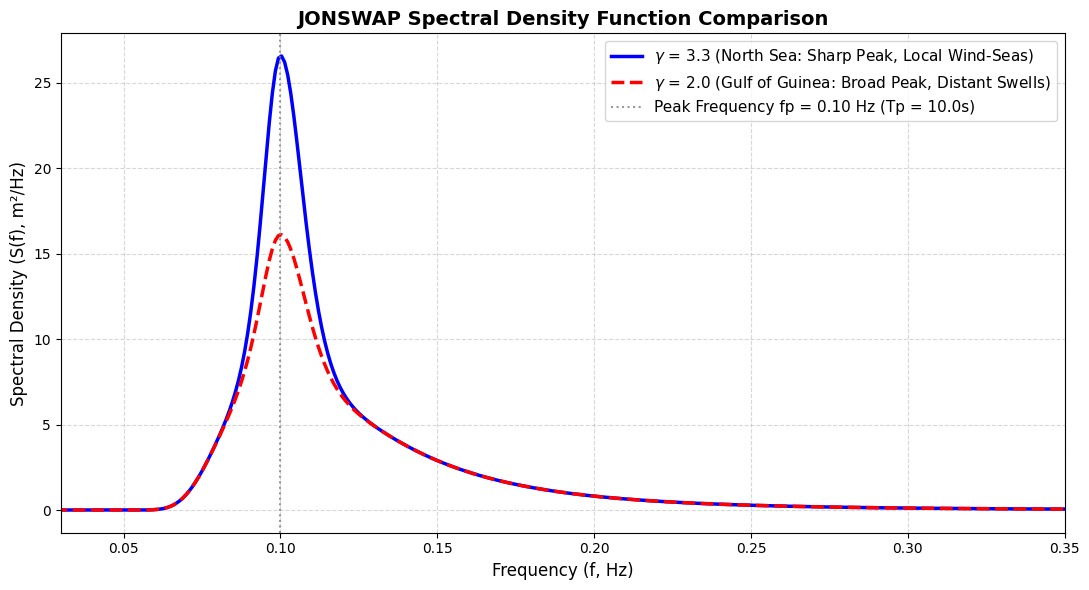

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def jonswap_spectrum(f, Tp, Hs, gamma):
    """
    Calculates the JONSWAP wave spectral density for a given array of frequencies.
    """
    fp = 1.0 / Tp
    # Sigma parameter based on frequency relative to peak frequency
    sigma = np.where(f <= fp, 0.07, 0.09)

    # Pierson-Moskowitz baseline spectrum (S_PM)
    # Alpha constant derived to match the target Hs
    alpha = (5.0 / 16.0) * (Hs**2) * (fp**4)
    S_PM = alpha * (f**-5) * np.exp(-1.25 * (f / fp)**-4)

    # Peak enhancement term
    r = np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2)))
    S_JONSWAP = S_PM * (gamma**r)

    return S_JONSWAP

# --- Simulation Parameters ---
Hs_target = 3.0    # 3.0 meters significant wave height
Tp_target = 10.0   # 10.0 seconds peak period
freqs = np.linspace(0.01, 0.5, 500) # Frequency range (Hz)

# Compute spectral density for both gammas
S_gamma_33 = jonswap_spectrum(freqs, Tp_target, Hs_target, gamma=3.3)
S_gamma_20 = jonswap_spectrum(freqs, Tp_target, Hs_target, gamma=2.0)

# --- Plotting the Spectral Curves ---
plt.figure(figsize=(11, 6))
plt.plot(freqs, S_gamma_33, 'b-', label=r'$\gamma$ = 3.3 (North Sea: Sharp Peak, Local Wind-Seas)', linewidth=2.5)
plt.plot(freqs, S_gamma_20, 'r--', label=r'$\gamma$ = 2.0 (Gulf of Guinea: Broad Peak, Distant Swells)', linewidth=2.5)

# Highlight the Peak Frequency
plt.axvline(1.0/Tp_target, color='gray', linestyle=':', alpha=0.8, label=f'Peak Frequency fp = {1.0/Tp_target:.2f} Hz (Tp = {Tp_target}s)')

plt.title('JONSWAP Spectral Density Function Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Frequency (f, Hz)', fontsize=12)
plt.ylabel('Spectral Density (S(f), m²/Hz)', fontsize=12)
plt.xlim(0.03, 0.35)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()